# Прогнозирование оттока абонентов телеком-оператора

Задача проекта — оценить вероятность ухода клиента
и определить характеристики, связанные с оттоком.

Цель этого ноутбука — изучить состав и качество данных,
исследовать закономерности и подготовить предложения
для последующего построения модели.

**Этап работы:** разведочный анализ данных (EDA).

## 1. Источник и загрузка данных

В проекте используется датасет
[Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

Исходный CSV читается с помощью pandas.

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import phik
import seaborn as sns

data_dir = kagglehub.dataset_download(
    "blastchar/telco-customer-churn/versions/1",
    output_dir="../data/raw",
)

df = pd.read_csv(
    f"{data_dir}/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

In [2]:
# Смотрим данные
df.sample(7).T

,2284,1398,6178,1060,4478,416,4599
customerID,8963-JLGJT,3569-EDBPQ,3719-TDVQB,6100-FJZDG,0988-JRWWP,4686-GEFRM,1834-ABKHQ
gender,Male,Female,Female,Male,Female,Male,Female
SeniorCitizen,0,0,1,0,0,0,0
Partner,No,No,Yes,Yes,No,Yes,Yes
Dependents,Yes,No,No,Yes,No,No,Yes
tenure,3,24,54,26,3,70,52
PhoneService,Yes,Yes,Yes,Yes,Yes,Yes,Yes
MultipleLines,No,Yes,No,No,No,Yes,No
InternetService,DSL,Fiber optic,No,No,DSL,Fiber optic,DSL
OnlineSecurity,Yes,Yes,No internet service,No internet service,No,No,No


In [3]:
# Смотрим исходные типы столбцов и количество непустых значений.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Пропуски, распознанные pandas

Посчитаем количество отсутствующих значений в каждом столбце.

In [4]:
missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

if missing_counts.empty:
    print("Пропусков, распознанных pandas, нет.")
else:
    display(missing_counts.to_frame(name="Количество пропусков"))

Пропусков, распознанных pandas, нет.


### Пустые и пробельные строки

Проверим текстовые поля.

In [5]:
blank_counts = {}
text_columns = df.select_dtypes(include=str).columns

# Считаем пустые и пробельные значения в каждом текстовом столбце.
for column in text_columns:
    trimmed_text = df[column].str.strip()
    blank_counts[column] = trimmed_text.eq("").sum()

blank_counts_series = pd.Series(blank_counts)
columns_with_blanks = blank_counts_series[blank_counts_series > 0]

if columns_with_blanks.empty:
    print("Пустых и пробельных строк нет.")
else:
    display(columns_with_blanks.to_frame(name="Пустые и пробельные строки"))

,Пустые и пробельные строки
TotalCharges,11


### Разбор пропусков в TotalCharges

In [6]:
# Отмечаем записи, где общая сумма пустая или состоит из пробелов.
blank_total_charges = df["TotalCharges"].str.strip().eq("")

# Отбираем отмеченные записи со всеми столбцами.
rows_without_total_charges = df.loc[blank_total_charges]

rows_without_total_charges.T

,488,753,936,1082,1340,3331,3826,4380,5218,6670,6754
customerID,4472-LVYGI,3115-CZMZD,5709-LVOEQ,4367-NUYAO,1371-DWPAZ,7644-OMVMY,3213-VVOLG,2520-SGTTA,2923-ARZLG,4075-WKNIU,2775-SEFEE
gender,Female,Male,Female,Male,Female,Male,Male,Female,Male,Female,Male
SeniorCitizen,0,0,0,0,0,0,0,0,0,0,0
Partner,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No
Dependents,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes
tenure,0,0,0,0,0,0,0,0,0,0,0
PhoneService,No,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes
MultipleLines,No phone service,No,No,Yes,No phone service,No,Yes,No,No,Yes,Yes
InternetService,DSL,No,DSL,No,DSL,No,No,No,No,DSL,DSL
OnlineSecurity,Yes,No internet service,Yes,No internet service,Yes,No internet service,No internet service,No internet service,No internet service,No,Yes


### Связь пропусков со сроком обслуживания

Сравним количество заполненных и пустых значений `TotalCharges`
у абонентов с нулевым сроком обслуживания и у остальных.

In [7]:
zero_tenure = df["tenure"].eq(0)

print("Пустой TotalCharges")
print("tenure = 0 —", blank_total_charges[zero_tenure].sum(), "из", zero_tenure.sum())
print("tenure ≠ 0 —", blank_total_charges[~zero_tenure].sum(), "из", (~zero_tenure).sum())

Пустой TotalCharges
tenure = 0 — 11 из 11
tenure ≠ 0 — 0 из 7032


### Обработка пропусков в `TotalCharges`

У всех 11 абонентов с `tenure = 0` общая сумма начислений
`TotalCharges` отсутствует. У остальных 7032 абонентов сумма указана.

Для подготовки данных принимаем допущение, что у абонентов
с нулевым сроком обслуживания и отсутствующей суммой - начисления
ещё не сформировались. Поэтому заполняем эти 11 пропусков нулём
и сохраняем все записи об абонентах.

Также преобразуем строковый формат данных в числовой для возможности дальнейших расчётов.

После преобразования подставленные нули будут учитываться
в статистиках по `TotalCharges` и при обучении модели.

In [8]:
# Выбираем строки с пустым TotalCharges и tenure = 0.
fill_with_zero = blank_total_charges & zero_tenure

# Подставляем текстовый "0", затем преобразуем весь столбец в числа.
total_charges_text = df["TotalCharges"].mask(fill_with_zero, "0")
df["TotalCharges"] = pd.to_numeric(total_charges_text, errors="raise")

print("Заполнено нулём:", fill_with_zero.sum())
print("Пропусков в TotalCharges:", df["TotalCharges"].isna().sum())

Заполнено нулём: 11
Пропусков в TotalCharges: 0


### Проверка дубликатов

Проверим наличие полных дубликатов строк и повторяющихся значений
`customerID`.

Если обнаружатся повторения, рассмотрим соответствующие записи
перед принятием решения об их обработке.

In [9]:
# Считаем повторные строки, совпадающие по всем столбцам.
duplicate_rows = df.duplicated().sum()

# Проверяем повторения идентификатора клиента.
duplicate_ids = df["customerID"].duplicated().sum()

print("Полных дубликатов строк:", duplicate_rows)
print("Повторных значений customerID:", duplicate_ids)

Полных дубликатов строк: 0
Повторных значений customerID: 0


Полные дубликаты строк и повторяющиеся значения `customerID`
не обнаружены. В текущем наборе данных каждому клиенту
соответствует одна запись.

### Совпадающие записи при разных customerID

Проверим, встречаются ли записи, совпадающие по всем столбцам
кроме `customerID`.

Такие совпадения рассмотрим отдельно.

In [10]:
# Сравниваем все значения, кроме идентификатора клиента.
profile_columns = df.columns.drop("customerID")

# Отмечаем все строки каждой группы совпадений, включая первую.
matching_profiles = df.duplicated(
    subset=profile_columns,
    keep=False,
)

if matching_profiles.any():
    print("Записей в группах совпадений:", matching_profiles.sum())

    # Располагаем совпадающие записи рядом и показываем несколько примеров.
    display(
        df.loc[matching_profiles]
        .sort_values(list(profile_columns))
        .head(6)
        .T
    )
else:
    print("Записей, совпадающих по всем значениям кроме customerID, нет.")

Записей в группах совпадений: 42


,6491,6764,4495,6267,5522,5759
customerID,9728-FTTVZ,7660-HDPJV,4702-IOQDC,0328-GRPMV,2619-WFQWU,9985-MWVIX
gender,Female,Female,Female,Female,Female,Female
SeniorCitizen,0,0,0,0,0,0
Partner,No,No,No,No,No,No
Dependents,No,No,No,No,No,No
tenure,1,1,1,1,1,1
PhoneService,Yes,Yes,Yes,Yes,Yes,Yes
MultipleLines,No,No,No,No,No,No
InternetService,Fiber optic,Fiber optic,Fiber optic,Fiber optic,Fiber optic,Fiber optic
OnlineSecurity,No,No,No,No,No,No


### Решение по совпадающим записям

Обнаружены 42 записи, у которых совпадают все значения,
кроме `customerID`. Идентификаторы этих записей различаются.

Возможное объяснение — разные клиенты имеют одинаковые
характеристики в пределах доступных столбцов: набор услуг,
тип договора, срок обслуживания, начисления и другие признаки.
Датасет не содержит полной информации о каждом человеке,
поэтому совпадение представленных характеристик возможно.

Само совпадение значений не доказывает, что один клиент
ошибочно записан несколько раз. При этом разные идентификаторы
также не позволяют окончательно исключить ошибку источника.

Для текущего анализа сохраняем эти записи. Достаточных оснований
для удаления не получено.

### Уточнение типа SeniorCitizen

`SeniorCitizen` обозначает принадлежность клиента к группе
пожилых людей. Числа `0` и `1` являются кодами категорий,
а не возрастом клиента.

Проверим встречающиеся значения перед преобразованием
столбца в категориальный тип.

In [11]:
df["SeniorCitizen"].value_counts(dropna=False)

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Для анализа представим `SeniorCitizen` как категориальный признак:
`0` соответствует `No`, `1` соответствует `Yes`.
Это позволит рассматривать его вместе с другими категориальными
признаками отдельно от количественных показателей.

In [12]:
# Заменяем числовые коды понятными обозначениями категорий.
df["SeniorCitizen"] = (
    df["SeniorCitizen"]
    .map({0: "No", 1: "Yes"})
    .astype("category")
)

# Проверяем количество клиентов в каждой категории.
df["SeniorCitizen"].value_counts(dropna=False)

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

### Проверка числовых значений

Рассмотрим сводную статистику числовых столбцов.
Необычные значения будем рассматривать отдельно.

In [13]:
# Получаем сводную статистику числовых столбцов.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


В количественных признаках отсутствуют распознанные пропуски
и отрицательные значения. Срок обслуживания составляет
от 0 до 72 месяцев.

Среднее значение `TotalCharges` заметно превышает медиану.

В статистике `TotalCharges` учитываются 11 нулей, подставленных
на основании принятого допущения об отсутствии начислений
у клиентов с `tenure = 0`.

### Распределения числовых признаков

Исследуем распределения `tenure`, `MonthlyCharges` и `TotalCharges`.

С помощью гистограмм определим, какие значения встречаются чаще,
есть ли выраженные пики и асимметрия распределений.

При интерпретации `TotalCharges` учитываем, что 11 отсутствовавших
значений ранее были заменены нулями на основании принятого допущения.

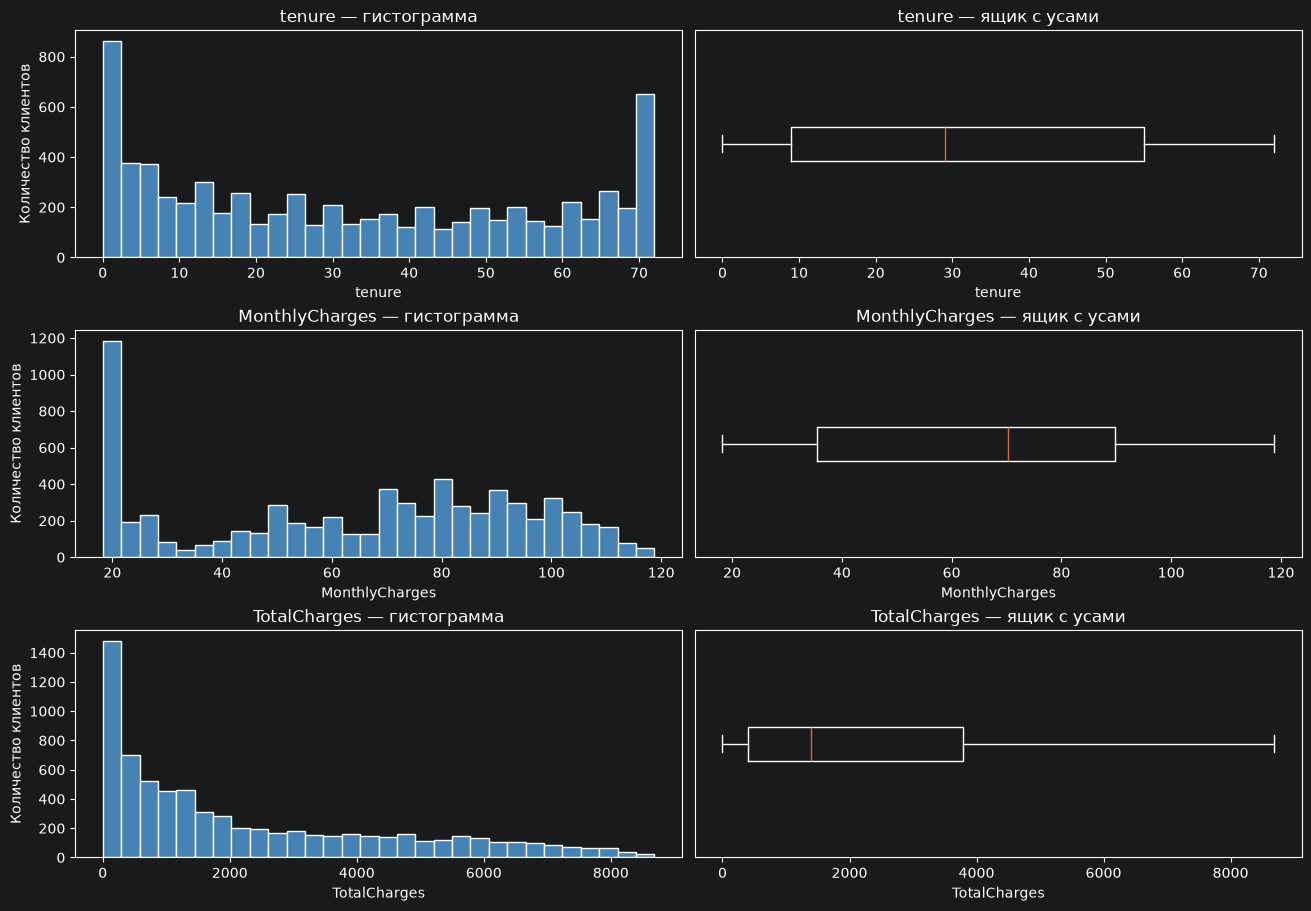

In [14]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 9),
    layout="constrained",
)

for row, column in enumerate(numeric_columns):
    values = df[column]

    hist_ax = axes[row, 0]
    hist_ax.hist(values, bins=30, color="steelblue", edgecolor="white")
    hist_ax.set_title(f"{column} — гистограмма")
    hist_ax.set_xlabel(column)
    hist_ax.set_ylabel("Количество клиентов")

    box_ax = axes[row, 1]
    box_ax.boxplot(values, orientation="horizontal")
    box_ax.set_title(f"{column} — ящик с усами")
    box_ax.set_xlabel(column)
    box_ax.set_yticks([])

plt.show()

Распределение `tenure` имеет выраженные скопления наблюдений
при небольшом сроке обслуживания и около верхней границы диапазона.
В выборке представлены как недавно подключившиеся клиенты,
так и клиенты с длительным сроком обслуживания.

В распределении `MonthlyCharges` заметен пик около 20
и широкое скопление значений примерно в диапазоне 70–100.
Возможная связь этой структуры с набором подключённых услуг
требует отдельной проверки.

Распределение `TotalCharges` имеет правостороннюю асимметрию:
наблюдения сосредоточены преимущественно в области небольших сумм,
а к высоким значениям тянется длинный хвост.

### Проверка категорий и их распределений

Для каждого категориального признака построим диаграмму
количества клиентов по категориям. Числа рядом с полосами
показывают точное количество записей.

Рассмотрим встречающиеся категории, соотношение размеров групп
и редкие значения. На всех диаграммах используем одинаковый
масштаб количества клиентов для корректного сравнения.

Идентификатор `customerID` исключаем, поскольку его уникальность
уже проверена.

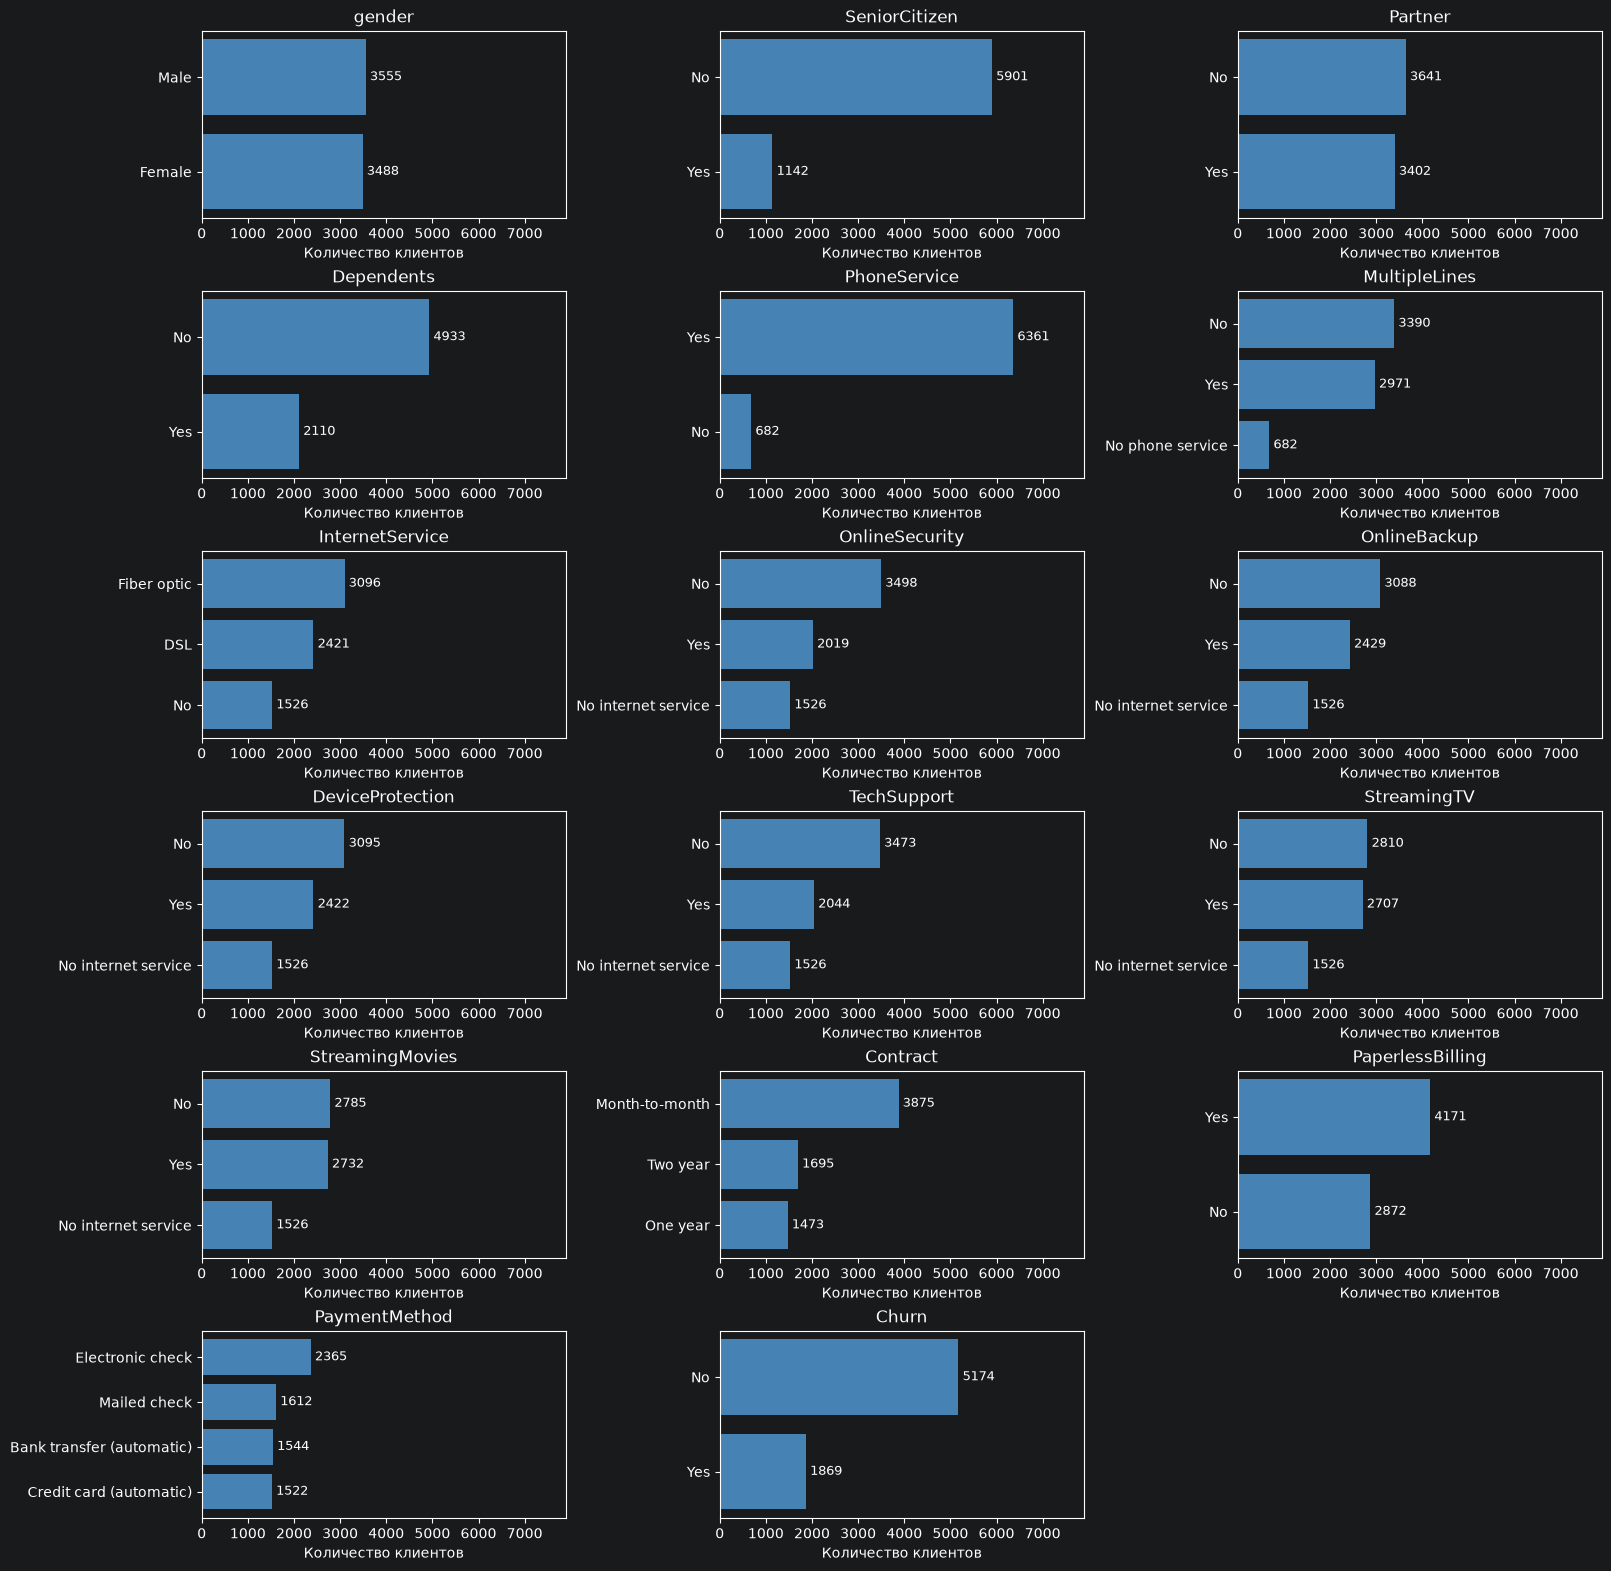

In [15]:
# Выбираем текстовые и категориальные признаки без идентификатора.
categorical_columns = (
    df.select_dtypes(include=["str", "category"])
    .columns.drop("customerID")
)

n_rows = (len(categorical_columns) + 2) // 3
fig, axes = plt.subplots(
    n_rows, 3,
    figsize=(16, 2.6 * n_rows),
    layout="constrained",
)
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    counts = df[column].value_counts(dropna=False)

    bars = ax.barh(
        counts.index.astype(str),
        counts.values,
        color="steelblue",
    )
    ax.bar_label(bars, padding=3, fontsize=9)

    # Располагаем наиболее частую категорию сверху.
    ax.invert_yaxis()
    ax.set_title(column)
    ax.set_xlabel("Количество клиентов")

    ax.set_xlim(0, len(df) * 1.12)

for ax in axes[len(categorical_columns):]:
    ax.set_visible(False)

plt.show()

По представленным названиям категорий и их частотам
явных проблем не обнаружено.

В целевой переменной `Churn` наблюдается дисбаланс классов:
5174 клиента остались (`No`), 1869 ушли (`Yes`).

Эти графики описывают состав выборки. Для изучения связи признаков
с оттоком далее сравним доли ушедших клиентов внутри разных групп.

### Связь числовых признаков с оттоком

Сравним распределения `tenure`, `MonthlyCharges` и `TotalCharges`
у оставшихся клиентов (`Churn = No`) и ушедших (`Churn = Yes`).

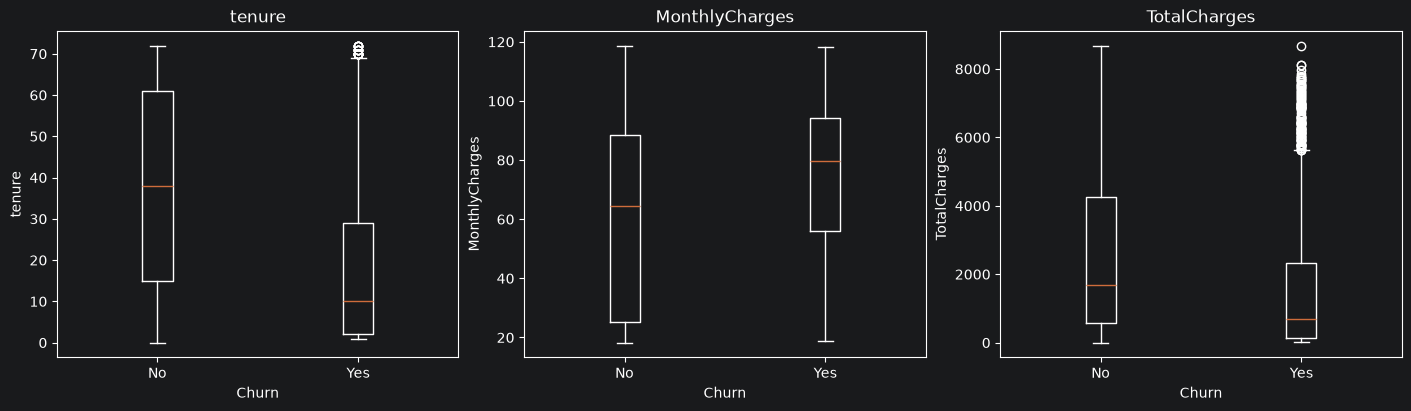

In [16]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4),
    layout="constrained",
)

for ax, column in zip(axes, numeric_columns):
    # Отбираем значения признака отдельно для каждой группы.
    stayed = df.loc[df["Churn"] == "No", column]
    churned = df.loc[df["Churn"] == "Yes", column]

    # Сравниваем две группы на одной шкале.
    ax.boxplot(
        [stayed, churned],
        tick_labels=["No", "Yes"],
    )
    ax.set_title(column)
    ax.set_xlabel("Churn")
    ax.set_ylabel(column)

plt.show()

In [17]:
# Разделяем клиентов по Churn и считаем медиану каждого признака.
df.groupby("Churn")[numeric_columns].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


У ушедших клиентов медианный срок обслуживания составляет
10 месяцев, у оставшихся — 38 месяцев. Таким образом, в этой
выборке уход связан с меньшим сроком обслуживания.

Медианные ежемесячные начисления у ушедших клиентов выше:
79,650 против 64,425. При этом медианные общие начисления ниже:
703,550 против 1679,525. Возможное объяснение меньшей накопленной
суммы — более короткий срок обслуживания.

Распределения групп перекрываются.

### Доля оттока в зависимости от срока обслуживания

При сравнении групп `Churn` обнаружено, что у ушедших клиентов
медианный срок обслуживания меньше.

Проверим, как различается доля ушедших клиентов между интервалами
`tenure`. Для первоначального обзора используем годовые интервалы,
включив нулевой срок обслуживания в первую группу.

Для каждой группы покажем общее количество клиентов,
количество ушедших и долю оттока. Полученные доли описывают
наблюдения в текущей выборке.

In [18]:
# Распределяем клиентов по интервалам срока обслуживания.
tenure_group = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=["0–12", "13–24", "25–36", "37–48", "49–60", "61–72"],
    include_lowest=True,
)

# Отмечаем ушедших клиентов.
is_churned = df["Churn"].eq("Yes")

# Для каждого интервала считаем всех клиентов и ушедших.
churn_by_tenure = (
    is_churned.groupby(tenure_group, observed=True)
    .agg(clients="size", churned="sum")
)

# Рассчитываем процент ушедших внутри каждой группы.
churn_by_tenure["churn_rate_pct"] = (
    churn_by_tenure["churned"] / churn_by_tenure["clients"] * 100
)

churn_by_tenure.round(1)

,clients,churned,churn_rate_pct
tenure,,,
0–12,2186,1037,47.4
13–24,1024,294,28.7
25–36,832,180,21.6
37–48,762,145,19.0
49–60,832,120,14.4
61–72,1407,93,6.6


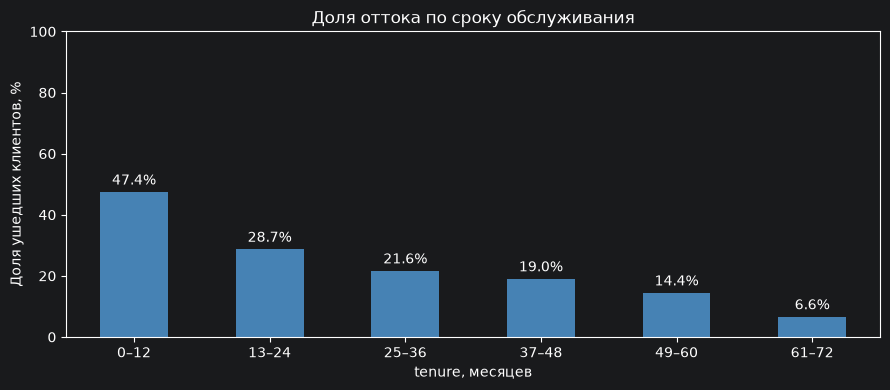

In [19]:
ax = churn_by_tenure["churn_rate_pct"].plot.bar(
    figsize=(9, 4),
    color="steelblue",
    rot=0,
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set_title("Доля оттока по сроку обслуживания")
ax.set_xlabel("tenure, месяцев")
ax.set_ylabel("Доля ушедших клиентов, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

В выбранных интервалах срока обслуживания доля оттока
последовательно снижается.

В группе `tenure = 0–12` ушли 1037 из 2186 клиентов (47,4%),
а в группе `61–72` — 93 из 1407 клиентов (6,6%).

Таким образом, в текущей выборке небольшой срок обслуживания
связан с более высокой долей оттока. Наблюдаемая связь
сама по себе не устанавливает причину ухода клиентов.

### Связь типа договора с оттоком

Сравним долю ушедших клиентов для трёх типов договора:
`Month-to-month`, `One year` и `Two year`.

Для каждой категории рассчитаем количество клиентов,
количество ушедших и процент оттока внутри категории.
Расположим категории по увеличению срока договора.

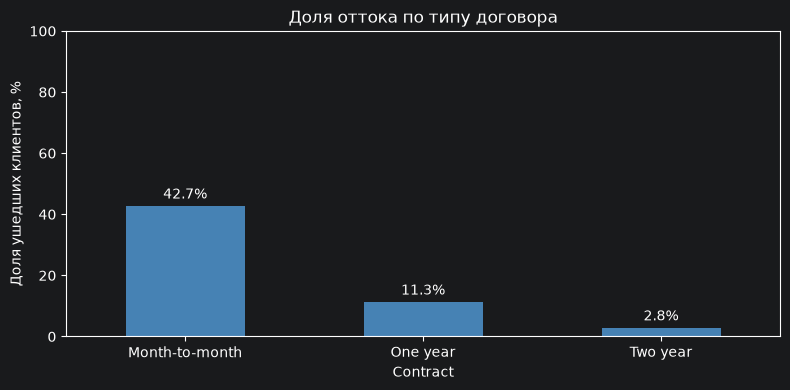

In [20]:
contract_order = ["Month-to-month", "One year", "Two year"]

# Считаем всех клиентов и ушедших внутри каждого типа договора.
churn_by_contract = (
    df["Churn"].eq("Yes")
    .groupby(df["Contract"], observed=True)
    .agg(clients="size", churned="sum")
    .reindex(contract_order)
)

# Рассчитываем долю оттока в процентах.
churn_by_contract["churn_rate_pct"] = (
    churn_by_contract["churned"] / churn_by_contract["clients"] * 100
)

churn_by_contract.style.format({"churn_rate_pct": "{:.1f}%"})

ax = churn_by_contract["churn_rate_pct"].plot.bar(
    figsize=(8, 4),
    color="steelblue",
    rot=0,
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set_title("Доля оттока по типу договора")
ax.set_xlabel("Contract")
ax.set_ylabel("Доля ушедших клиентов, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

Доля оттока различается между типами договора: для помесячных
договоров она выше, чем для годовых и двухлетних.

Возможные объяснения связаны с условиями расторжения договора
и различиями между клиентами, выбирающими разные сроки.
Эти объяснения остаются гипотезами.

### Связь категориальных признаков с оттоком

Сравним долю оттока внутри категорий остальных признаков.
Для каждой категории укажем процент ушедших клиентов
и общее количество клиентов в группе (`n`).

Пунктирная линия обозначает общую долю оттока в выборке.
Она служит ориентиром при сравнении групп.

Рассмотрим наиболее заметные различия и размеры групп.

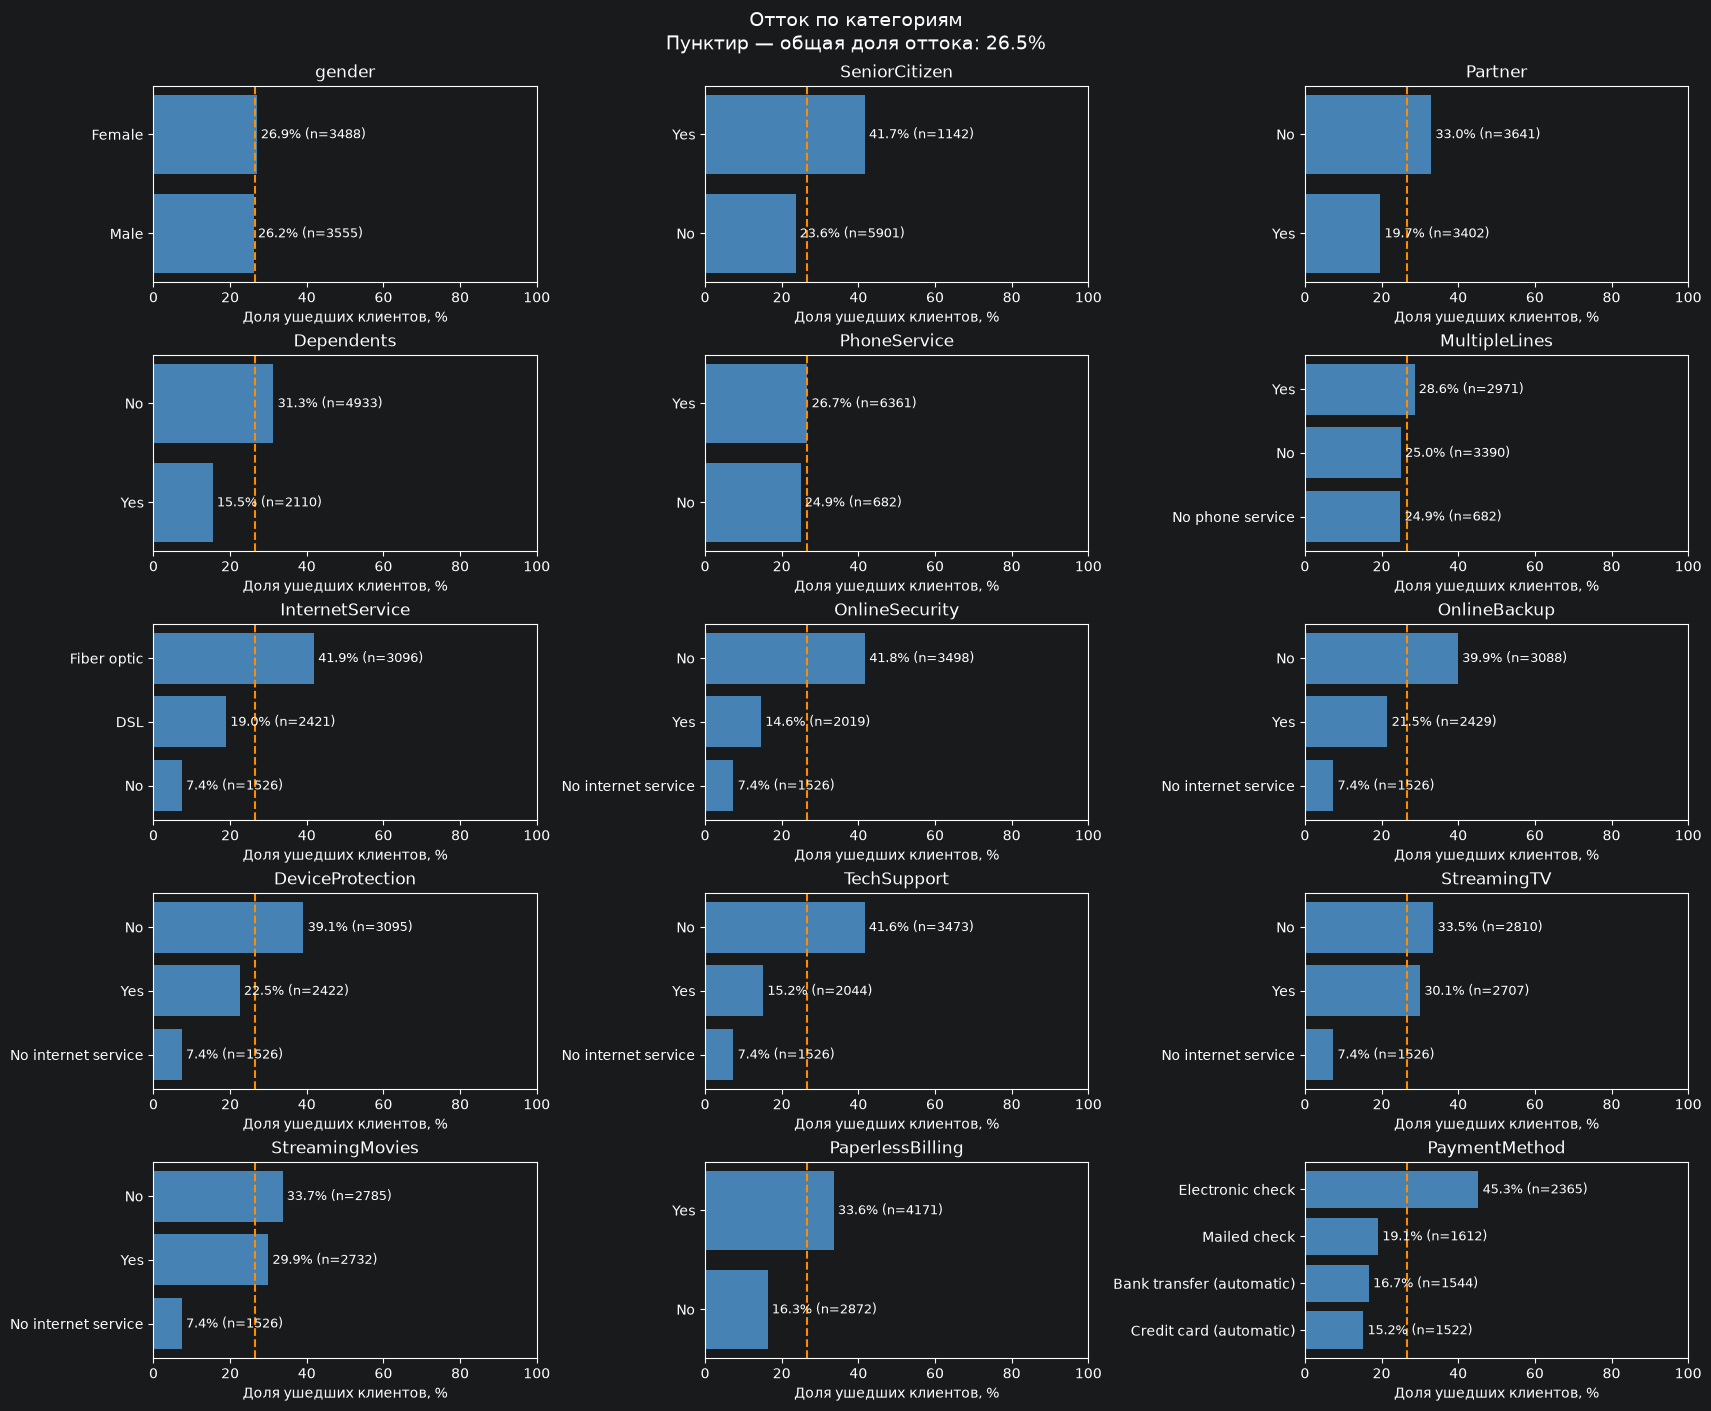

In [21]:
# Выбираем оставшиеся категориальные признаки.
columns_to_compare = (
    df.select_dtypes(include=["str", "category"])
    .columns.drop(["customerID", "Churn", "Contract"])
)

is_churned = df["Churn"].eq("Yes")
overall_churn_rate = is_churned.sum() / len(df) * 100

# Создаём сетку по три графика в ряд.
n_rows = (len(columns_to_compare) + 2) // 3
fig, axes = plt.subplots(
    n_rows, 3,
    figsize=(17, 2.8 * n_rows),
    layout="constrained",
)
axes = axes.flatten()

for ax, column in zip(axes, columns_to_compare):
    # Считаем размер каждой группы и количество ушедших.
    summary = (
        is_churned.groupby(df[column], observed=True, dropna=False)
        .agg(clients="size", churned="sum")
    )
    summary["churn_rate_pct"] = (
        summary["churned"] / summary["clients"] * 100
    )
    summary = summary.sort_values("churn_rate_pct", ascending=False)

    # Рисуем доли оттока и подписываем размеры групп.
    bars = ax.barh(
        summary.index.astype(str),
        summary["churn_rate_pct"],
        color="steelblue",
    )
    labels = [
        f"{rate:.1f}% (n={count})"
        for rate, count in zip(
            summary["churn_rate_pct"], summary["clients"]
        )
    ]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=9)

    # Добавляем общую долю оттока как ориентир.
    ax.axvline(
        overall_churn_rate,
        color="darkorange",
        linestyle="--",
    )
    ax.invert_yaxis()
    ax.set_title(column)
    ax.set_xlabel("Доля ушедших клиентов, %")
    ax.set_xlim(0, 100)

# Скрываем свободные области.
for ax in axes[len(columns_to_compare):]:
    ax.set_visible(False)

fig.suptitle(
    f"Отток по категориям\n"
    f"Пунктир — общая доля оттока: {overall_churn_rate:.1f}%",
    fontsize=14,
)

plt.show()

Заметные различия долей оттока наблюдаются между категориями
`InternetService`, `PaymentMethod`, `OnlineSecurity`,
`TechSupport` и `SeniorCitizen`.

Полученные результаты описывают связи в выборке.
Они не позволяют установить самостоятельное влияние
каждого признака или причины ухода клиентов.

### Связи между признаками: тепловая карта φk

Рассчитаем попарные связи между признаками и целевой переменной
`Churn` с помощью коэффициента φk. Метод позволяет совместно
рассматривать числовые и категориальные признаки.

Идентификатор `customerID` исключаем из расчёта.
Для числовых признаков используем разбиение на 10 интервалов
равной ширины.

Значения φk находятся в диапазоне от 0 до 1 и характеризуют
силу связи. Коэффициент не показывает её направление
и не устанавливает причинно-следственные отношения.

In [22]:
# Исключаем идентификатор из данных для расчёта.
data_for_phik = df.drop(columns=["customerID"])

# Явно указываем количественные признаки.
interval_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

# Рассчитываем матрицу попарных связей.
phik_matrix = data_for_phik.phik_matrix(
    interval_cols=interval_columns,
    bins=10,
    njobs=1,
)

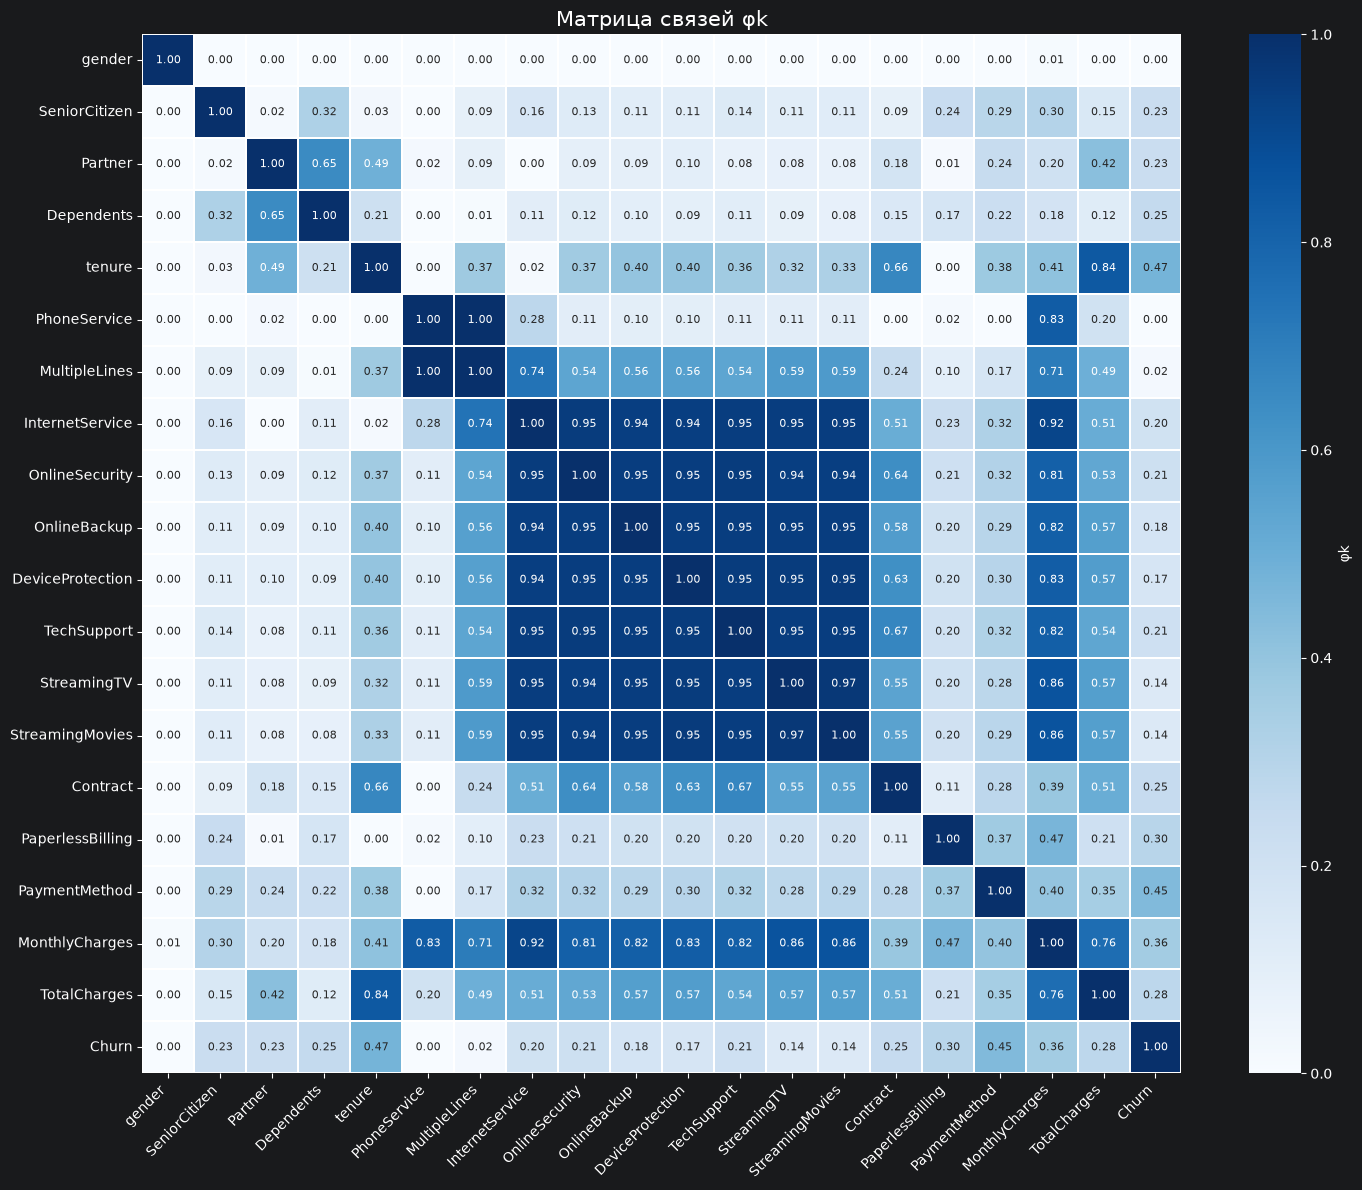

In [23]:
fig, ax = plt.subplots(figsize=(15, 12))

sns.heatmap(
    phik_matrix,
    annot=True,                  # Показываем числа внутри клеток.
    fmt=".2f",                   # Два знака после запятой.
    cmap="Blues",                # Чем темнее клетка, тем сильнее связь.
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.3,
    annot_kws={"size": 8},
    cbar_kws={"label": "φk"},
    ax=ax,
)

ax.set_title("Матрица связей φk", fontsize=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Среди рассчитанных попарных связей с `Churn` наибольшие значения
φk получены для `tenure` (0,47), `PaymentMethod` (0,45)
и `MonthlyCharges` (0,36).

Обнаружены тесные связи между самими признаками.
`TotalCharges` связан с `tenure` (0,84) и `MonthlyCharges` (0,76),
а `Contract` — с `tenure` (0,66).

Высокие значения φk между признаками услуг требуют отдельной
проверки.

Карта описывает попарные связи и не определяет самостоятельную
важность признаков для модели.

### Согласованность основных и дополнительных услуг

Покажем количество клиентов для содержательных сочетаний услуг.
Каждая полоса подписана полным описанием сочетания.

Синим обозначены согласованные ответы.
Красным выделена отдельная группа записей, в которых столбцы
по-разному сообщают о наличии основной услуги.
Ненулевой размер этой группы потребует просмотра конкретных записей.

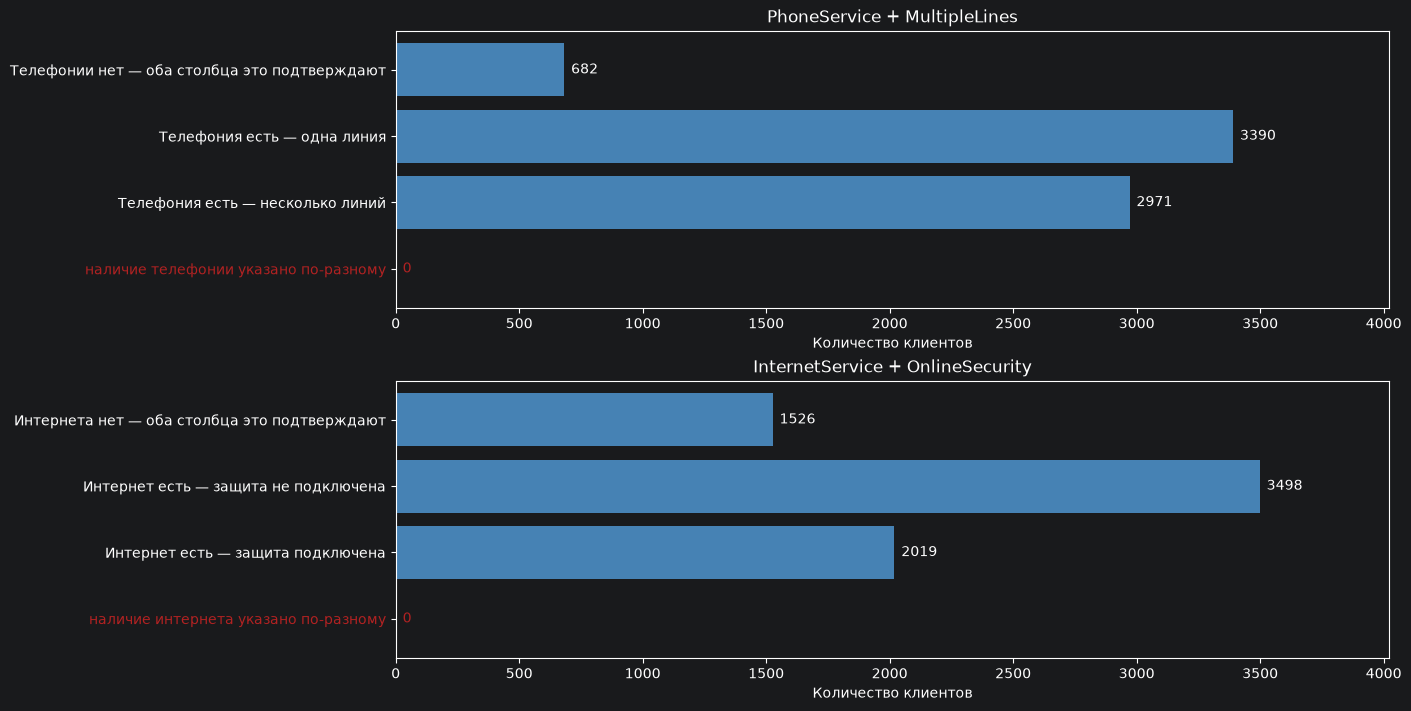

In [24]:
# Количество клиентов для каждого сочетания телефонных услуг.
phone_table = pd.crosstab(
    df["PhoneService"], df["MultipleLines"]
).reindex(
    index=["No", "Yes"],
    columns=["No phone service", "No", "Yes"],
)

# Количество клиентов для каждого сочетания интернета и защиты.
internet_table = pd.crosstab(
    df["InternetService"], df["OnlineSecurity"]
).reindex(
    index=["No", "DSL", "Fiber optic"],
    columns=["No internet service", "No", "Yes"],
)

phone_counts = pd.Series({
    "Телефонии нет — оба столбца это подтверждают":
        phone_table.loc["No", "No phone service"],

    "Телефония есть — одна линия":
        phone_table.loc["Yes", "No"],

    "Телефония есть — несколько линий":
        phone_table.loc["Yes", "Yes"],

    "наличие телефонии указано по-разному":
        phone_table.loc["No", ["No", "Yes"]].sum()
        + phone_table.loc["Yes", "No phone service"],
})

internet_counts = pd.Series({
    "Интернета нет — оба столбца это подтверждают":
        internet_table.loc["No", "No internet service"],

    "Интернет есть — защита не подключена":
        internet_table.loc[["DSL", "Fiber optic"], "No"].sum(),

    "Интернет есть — защита подключена":
        internet_table.loc[["DSL", "Fiber optic"], "Yes"].sum(),

    "наличие интернета указано по-разному":
        internet_table.loc["No", ["No", "Yes"]].sum()
        + internet_table.loc[
            ["DSL", "Fiber optic"], "No internet service"
        ].sum(),
})

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    layout="constrained",
)

# Используем одинаковую шкалу количества клиентов.
max_count = max(phone_counts.max(), internet_counts.max())

for ax, counts, title in zip(
    axes,
    [phone_counts, internet_counts],
    ["PhoneService + MultipleLines", "InternetService + OnlineSecurity"],
):
    bars = ax.barh(
        counts.index,
        counts.values,
        color=["steelblue", "steelblue", "steelblue", "firebrick"],
    )

    annotations = ax.bar_label(bars, fmt="%d", padding=5)
    annotations[-1].set_color("firebrick")

    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Количество клиентов")
    ax.set_xlim(0, max_count * 1.15)
    ax.get_yticklabels()[-1].set_color("firebrick")

plt.show()

В проверенных парах `PhoneService` — `MultipleLines`
и `InternetService` — `OnlineSecurity` несогласованных записей
не обнаружено.

Для всех 682 клиентов без телефонии в `MultipleLines`
указано `No phone service`. Для всех 1526 клиентов без интернета
в `OnlineSecurity` указано `No internet service`.

Таким образом, информация об отсутствии основной услуги
повторяется в дополнительных признаках. Это помогает объяснить
высокие значения связи на тепловой карте.

При этом столбцы содержат и дополнительную информацию:
о нескольких телефонных линиях, технологии интернет-подключения
и наличии защиты.

### Связь общих начислений со сроком обслуживания и ежемесячной суммой

Построим диаграммы рассеяния `TotalCharges` относительно
`tenure` и `MonthlyCharges`. Каждая точка соответствует клиенту.

Рассмотрим направление связи, разброс значений и наблюдения,
выделяющиеся на фоне остальных. Это поможет содержательно
интерпретировать высокие значения φk.

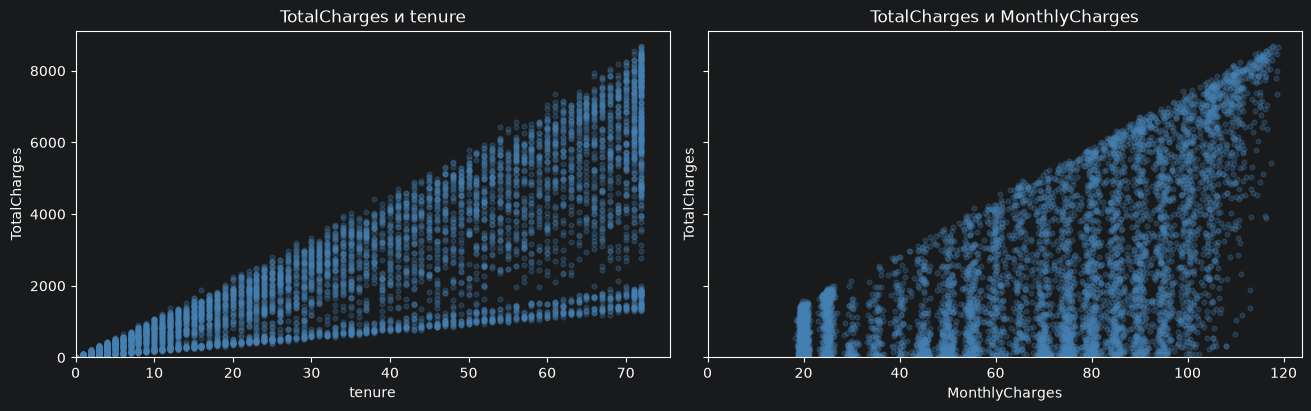

In [25]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4),
    sharey=True,
    layout="constrained",
)

for ax, column in zip(axes, ["tenure", "MonthlyCharges"]):
    # Каждая точка показывает два значения одного клиента.
    ax.scatter(
        df[column],
        df["TotalCharges"],
        s=12,
        alpha=0.25,
        color="steelblue",
    )

    ax.set_title(f"TotalCharges и {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("TotalCharges")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

plt.show()

Диаграммы показывают положительную связь `TotalCharges`
со сроком обслуживания и ежемесячными начислениями.

Форма распределений соответствует ожидаемому накоплению
начислений за время обслуживания. Явно изолированных наблюдений
далеко от основной массы на этих графиках не обнаружено.

### Тип договора и отток при похожем сроке обслуживания

Ранее обнаружены связи оттока с `Contract` и `tenure`,
а также связь этих признаков между собой.

Сравним доли оттока по типам договора отдельно внутри каждого
интервала `tenure`. Проверим, сохраняются ли различия,
когда срок обслуживания клиентов примерно сопоставим.

На графиках укажем долю ушедших и размер каждой группы (`n`).
Такое сравнение учитывает срок обслуживания приближённо
и не устанавливает причинное влияние договора.

In [26]:
# Группируем сразу по двум характеристикам:
# интервалу срока обслуживания и типу договора.
churn_by_tenure_contract = (
    df["Churn"].eq("Yes")
    .groupby([tenure_group, df["Contract"]], observed=True)
    .agg(clients="size", churned="sum")
)

# Для каждого сочетания считаем процент ушедших.
churn_by_tenure_contract["churn_rate_pct"] = (
    churn_by_tenure_contract["churned"]
    / churn_by_tenure_contract["clients"]
    * 100
)

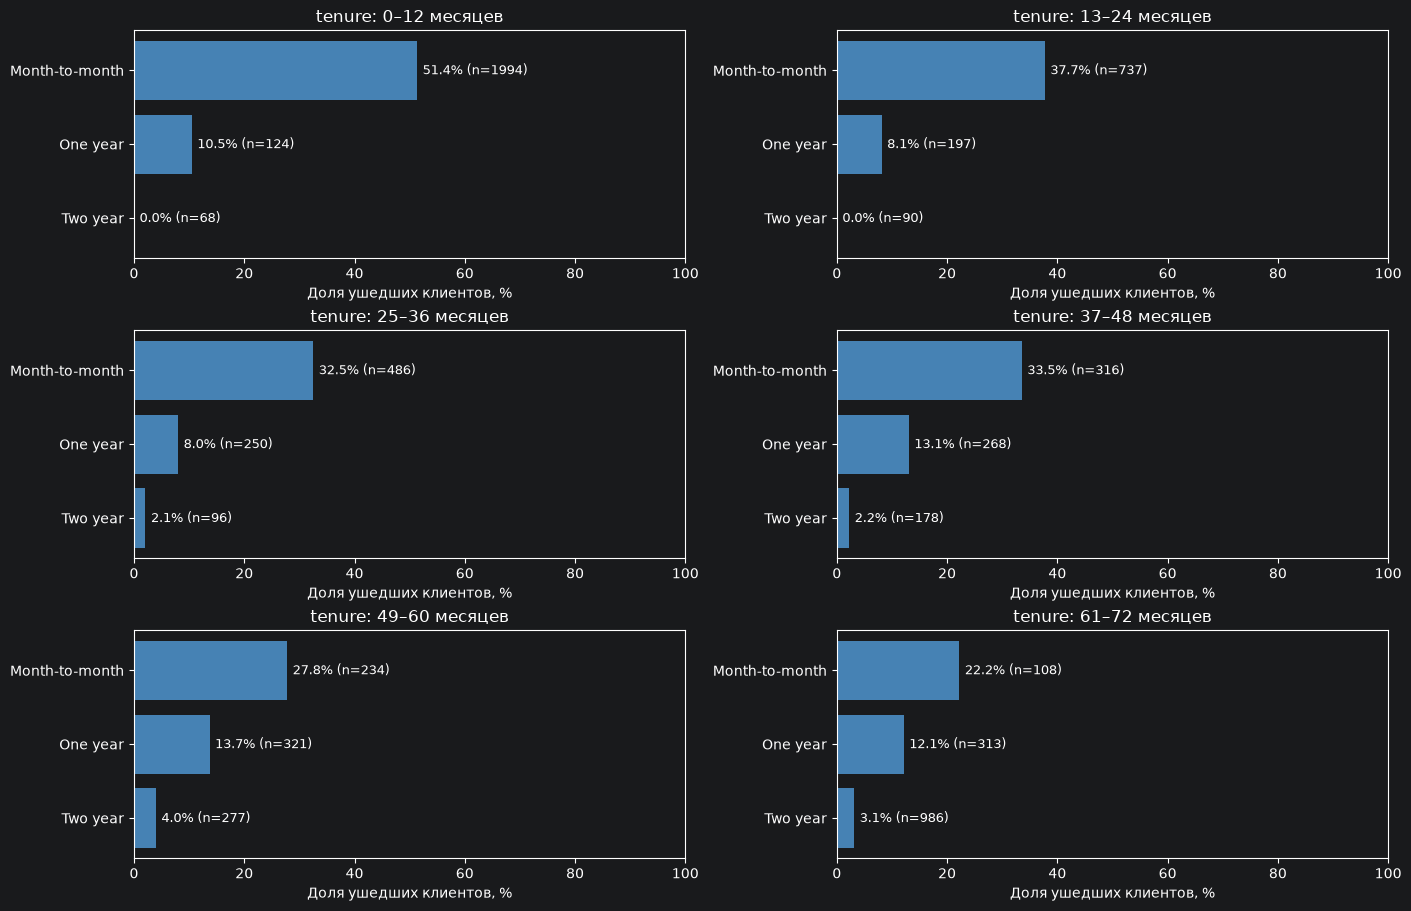

In [27]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 9),
    layout="constrained",
)

for ax, tenure_interval in zip(axes.flat, tenure_group.cat.categories):
    # Выбираем один интервал tenure и располагаем договоры по сроку.
    group_data = (
        churn_by_tenure_contract.loc[tenure_interval]
        .reindex(contract_order)
    )

    bars = ax.barh(
        group_data.index,
        group_data["churn_rate_pct"],
        color="steelblue",
    )

    labels = [
        f"{rate:.1f}% (n={count})"
        for rate, count in zip(
            group_data["churn_rate_pct"],
            group_data["clients"],
        )
    ]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=9)

    ax.invert_yaxis()
    ax.set_title(f"tenure: {tenure_interval} месяцев")
    ax.set_xlabel("Доля ушедших клиентов, %")
    ax.set_xlim(0, 100)

plt.show()

Во всех рассмотренных интервалах `tenure` наибольшая доля оттока
наблюдается у клиентов с помесячным договором, наименьшая —
с двухлетним.

Различия сохраняются и среди давно обслуживающихся клиентов.

Таким образом, различия между типами договора не исчезают
при сравнении внутри выбранных интервалов срока обслуживания.

Для помесячных договоров доля оттока в целом уменьшается
с увеличением срока обслуживания, однако снижение
не является строго последовательным.

## Итоги EDA

Изучены данные о 7043 клиентах. Доля оттока составляет 26,5%,
поэтому при оценке модели необходимо учитывать дисбаланс классов.

**Подготовка данных**
- 11 пустых `TotalCharges` при `tenure = 0` заполнены нулями
  на основании допущения об отсутствии начислений.
- Исправлены типы `TotalCharges` и `SeniorCitizen`.
- Полных дубликатов и повторяющихся `customerID` нет.
  42 записи с одинаковыми остальными значениями сохранены:
  ошибочное дублирование клиентов не доказано.

**Основные результаты**
- Доля оттока выше у клиентов с небольшим сроком обслуживания
  и помесячным договором. Различия между договорами сохраняются
  внутри рассмотренных интервалов `tenure`.
- У ушедших клиентов медианные ежемесячные начисления выше,
  а срок обслуживания и общие начисления ниже.
- Различия оттока обнаружены по типу интернета, способу оплаты,
  дополнительным услугам и `SeniorCitizen`.
  По `gender` выраженного различия не наблюдается.
- Некоторые признаки тесно связаны и частично повторяют информацию,
  что необходимо учитывать при моделировании.

**Ограничения и следующий этап**

Наблюдаемые связи не доказывают причины ухода клиентов.
Следующий этап — подготовка признаков и обучение модели
с проверкой на отдельной выборке. `customerID` исключается
из признаков. Помимо общей доли правильных ответов,
необходимо оценивать полноту и точность обнаружения оттока.